Saved C:\Users\shara\Downloads\input_costs_dashboard.png


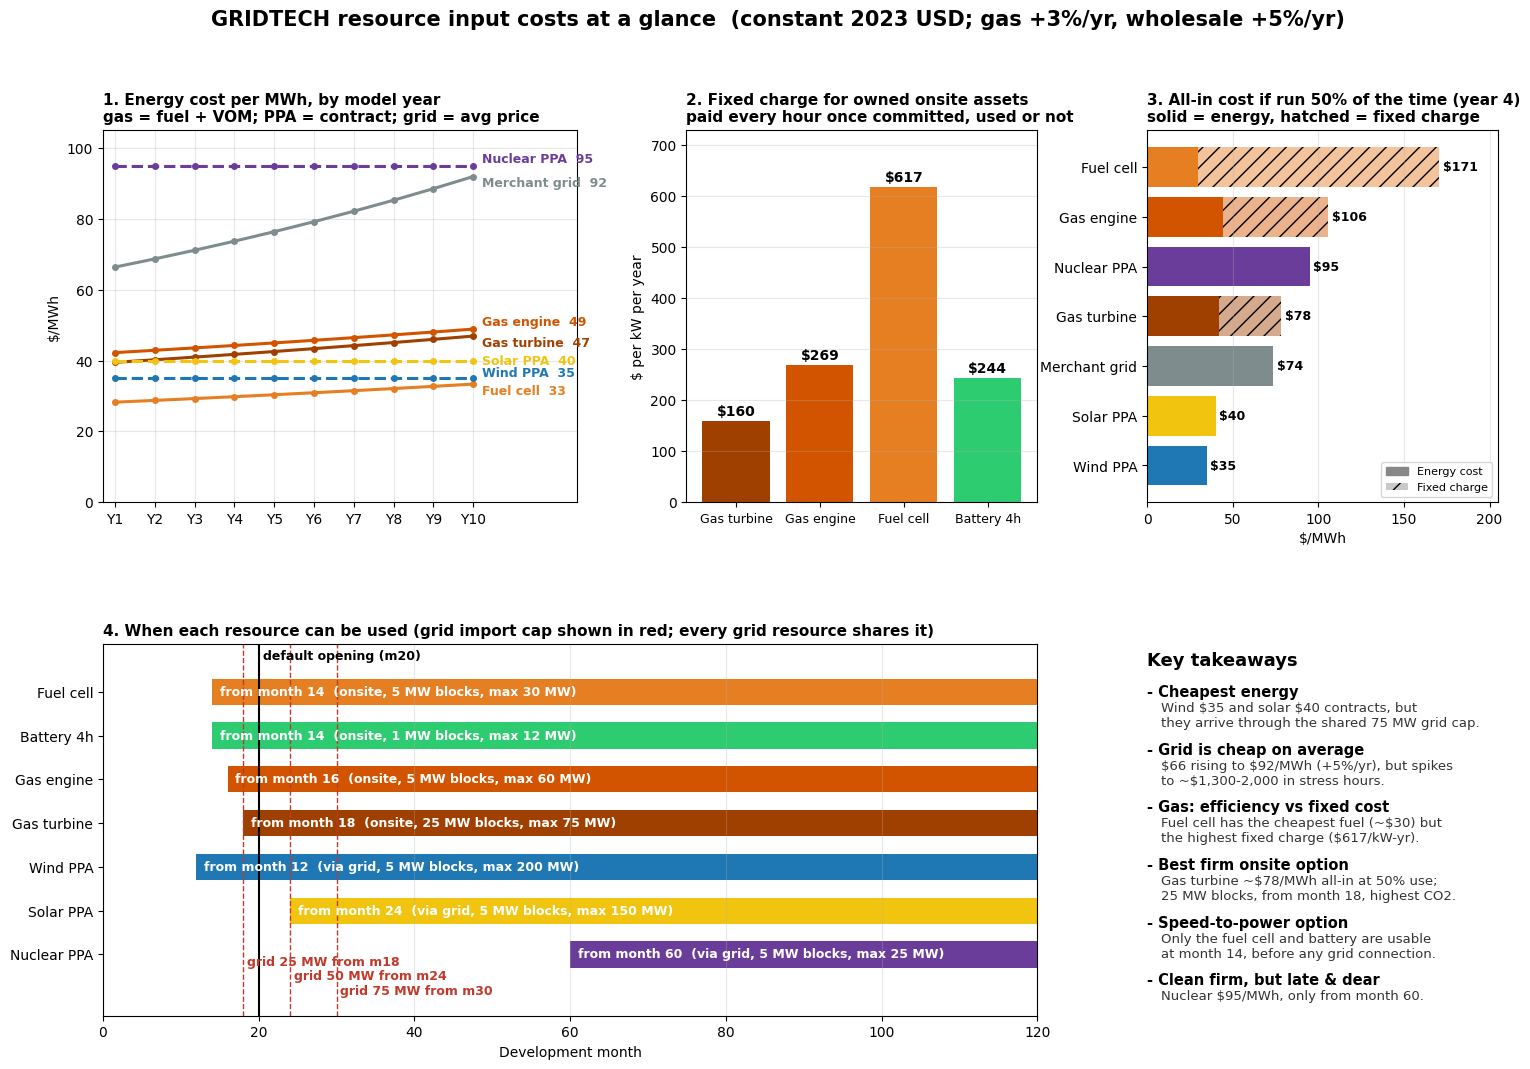

In [2]:
"""One-page dashboard of resource input costs (from timeline_default.csv + resource_options.csv)."""
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = None   # e.g. r"C:\Users\you\gridtech\data"; None -> a dialog asks for the data folder
if DATA_DIR is None:
    import tkinter as tk
    from tkinter import filedialog
    root = tk.Tk(); root.withdraw(); root.attributes("-topmost", True)
    DATA_DIR = filedialog.askdirectory(title="Select the data folder (timeline_default.csv + resource_options.csv)")
    root.destroy()
DATA_DIR = Path(DATA_DIR)

t = pd.read_csv(DATA_DIR / "timeline_default.csv",
                usecols=["model_year", "merchant_price_usd_per_mwh", "delivered_gas_price_usd_per_mmbtu"])
r = pd.read_csv(DATA_DIR / "resource_options.csv").set_index("option_id")
crf = lambda L: 0.08 / (1 - 1.08 ** -L)

y = t.groupby("model_year").mean()
yrs = y.index.values
gas = y.delivered_gas_price_usd_per_mmbtu.values

COL = {"Merchant grid": "#7f8c8d", "Gas turbine": "#a04000", "Gas engine": "#d35400",
       "Fuel cell": "#e67e22", "Solar PPA": "#f1c40f", "Wind PPA": "#1f78b4",
       "Nuclear PPA": "#6a3d9a", "Battery 4h": "#2ecc71"}
GAS = {"Gas turbine": "gas_turbine", "Gas engine": "gas_engine", "Fuel cell": "fuel_cell"}
PPA = {"Solar PPA": "utility_solar", "Wind PPA": "wind", "Nuclear PPA": "nuclear"}

energy = {"Merchant grid": y.merchant_price_usd_per_mwh.values}
for lab, o in GAS.items():
    energy[lab] = r.loc[o, "payment_usd_per_mwh"] + r.loc[o, "heat_rate_mmbtu_per_mwh_hhv"] * gas
for lab, o in PPA.items():
    energy[lab] = np.full(len(yrs), r.loc[o, "payment_usd_per_mwh"])
fixed_kw = {lab: r.loc[o, "capex_usd_per_kw"] * crf(r.loc[o, "life_years"]) + r.loc[o, "fom_usd_per_kw_year"]
            for lab, o in {**GAS, "Battery 4h": "battery_4h"}.items()}

fig = plt.figure(figsize=(18, 11.5))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1], width_ratios=[1.35, 1, 1], hspace=0.38, wspace=0.28)

# ---- (1) energy cost per MWh over the years
ax = fig.add_subplot(gs[0, 0])
NUDGE = {"Gas engine": 5, "Gas turbine": -5, "Nuclear PPA": 5, "Merchant grid": -5, "Wind PPA": 4, "Fuel cell": -5}
for lab, v in energy.items():
    ls = "--" if "PPA" in lab else "-"
    ax.plot(yrs, v, ls, marker="o", ms=4, lw=2.2, color=COL[lab])
    ax.annotate(f"{lab}  {v[-1]:.0f}", (yrs[-1], v[-1]), xytext=(6, NUDGE.get(lab, 0)), textcoords="offset points",
                va="center", fontsize=9, color=COL[lab], fontweight="bold")
ax.set_xticks(yrs); ax.set_xticklabels([f"Y{i}" for i in yrs])
ax.set_xlim(0.7, 12.6); ax.set_ylim(0, 105)
ax.set_ylabel("\\$/MWh")
ax.set_title("1. Energy cost per MWh, by model year\ngas = fuel + VOM; PPA = contract; grid = avg price",
             fontsize=11, fontweight="bold", loc="left")
ax.grid(alpha=0.3)

# ---- (2) fixed capacity charge
ax = fig.add_subplot(gs[0, 1])
labs = list(fixed_kw)
ax.bar(labs, fixed_kw.values(), color=[COL[l] for l in labs])
for i, v in enumerate(fixed_kw.values()):
    ax.text(i, v + 10, f"\\${v:.0f}", ha="center", fontweight="bold")
ax.set_ylabel("\\$ per kW per year")
ax.set_ylim(0, max(fixed_kw.values()) * 1.18)
ax.set_title("2. Fixed charge for owned onsite assets\npaid every hour once committed, used or not",
             fontsize=11, fontweight="bold", loc="left")
ax.tick_params(axis="x", labelsize=9); ax.grid(axis="y", alpha=0.3)

# ---- (3) all-in $/MWh at 50% utilisation, year 4 (stacked fixed + energy)
ax = fig.add_subplot(gs[0, 2])
Y = 4; cf = 0.5
items = ["Wind PPA", "Solar PPA", "Merchant grid", "Gas turbine", "Gas engine", "Nuclear PPA", "Fuel cell"]
var = [energy[i][Y - 1] for i in items]
fix = [fixed_kw.get(i, 0) * 1000 / (8760 * cf) for i in items]
order = np.argsort(np.array(var) + np.array(fix))
items = [items[i] for i in order]; var = [var[i] for i in order]; fix = [fix[i] for i in order]
ax.barh(items, var, color=[COL[i] for i in items], label="Energy cost")
ax.barh(items, fix, left=var, color=[COL[i] for i in items], alpha=0.45, hatch="//", label="Fixed charge")
for i, (a, b) in enumerate(zip(var, fix)):
    ax.text(a + b + 2, i, f"\\${a + b:.0f}", va="center", fontweight="bold", fontsize=9)
ax.set_xlim(0, max(np.array(var) + np.array(fix)) * 1.2)
ax.set_xlabel("\\$/MWh")
ax.set_title(f"3. All-in cost if run 50% of the time (year {Y})\nsolid = energy, hatched = fixed charge",
             fontsize=11, fontweight="bold", loc="left")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#888", label="Energy cost"), Patch(facecolor="#888", alpha=0.45, hatch="//", label="Fixed charge")],
          fontsize=8, loc="lower right"); ax.grid(axis="x", alpha=0.3)

# ---- (4) when each resource becomes available + grid steps
ax = fig.add_subplot(gs[1, 0:2])
avail = [("Fuel cell", "fuel_cell"), ("Battery 4h", "battery_4h"), ("Gas engine", "gas_engine"),
         ("Gas turbine", "gas_turbine"), ("Wind PPA", "wind"), ("Solar PPA", "utility_solar"),
         ("Nuclear PPA", "nuclear")]
for i, (lab, o) in enumerate(avail):
    m0 = r.loc[o, "available_month"]
    ax.barh(i, 120 - m0, left=m0, color=COL[lab], height=0.6)
    loc = "onsite" if r.loc[o, "location"] == "onsite" else "via grid"
    mx = 75 if o == "gas_turbine" else r.loc[o, "max_mw"]
    ax.text(m0 + 1, i, f"from month {m0}  ({loc}, {r.loc[o, 'block_mw']} MW blocks, max {mx} MW)",
            va="center", fontsize=9, color="white", fontweight="bold")
ax.set_yticks(range(len(avail))); ax.set_yticklabels([a[0] for a in avail])
for k, (m, mw) in enumerate([(18, 25), (24, 50), (30, 75)]):
    ax.axvline(m, color="#c0392b", ls="--", lw=1)
    ax.text(m + 0.5, len(avail) - 0.75 + 0.33 * k, f"grid {mw} MW from m{m}", color="#c0392b",
            fontsize=9, fontweight="bold")
ax.axvline(20, color="k", lw=1.5); ax.text(20.5, -0.75, "default opening (m20)", fontsize=9, fontweight="bold")
ax.set_xlim(0, 120); ax.set_ylim(-1.1, len(avail) + 0.4); ax.invert_yaxis()
ax.set_xlabel("Development month")
ax.set_title("4. When each resource can be used (grid import cap shown in red; every grid resource shares it)",
             fontsize=11, fontweight="bold", loc="left")
ax.grid(axis="x", alpha=0.3)

# ---- (5) key takeaways
ax = fig.add_subplot(gs[1, 2]); ax.axis("off")
notes = [
    ("Cheapest energy", "Wind \\$35 and solar \\$40 contracts, but\nthey arrive through the shared 75 MW grid cap."),
    ("Grid is cheap on average", "\\$66 rising to \\$92/MWh (+5%/yr), but spikes\nto ~\\$1,300-2,000 in stress hours."),
    ("Gas: efficiency vs fixed cost", "Fuel cell has the cheapest fuel (~\\$30) but\nthe highest fixed charge (\\$617/kW-yr)."),
    ("Best firm onsite option", "Gas turbine ~\\$78/MWh all-in at 50% use;\n25 MW blocks, from month 18, highest CO2."),
    ("Speed-to-power option", "Only the fuel cell and battery are usable\nat month 14, before any grid connection."),
    ("Clean firm, but late & dear", "Nuclear \\$95/MWh, only from month 60."),
]
yy = 0.98
ax.text(0, yy, "Key takeaways", fontsize=13, fontweight="bold", transform=ax.transAxes, va="top")
yy -= 0.09
for head, body in notes:
    ax.text(0, yy, "- " + head, fontsize=10.5, fontweight="bold", transform=ax.transAxes, va="top")
    ax.text(0.04, yy - 0.045, body, fontsize=9.5, transform=ax.transAxes, va="top", color="#333")
    yy -= 0.155

fig.suptitle("GRIDTECH resource input costs at a glance  (constant 2023 USD; gas +3%/yr, wholesale +5%/yr)",
             fontsize=15, fontweight="bold", y=0.985)
out_png = DATA_DIR.parent / "input_costs_dashboard.png"
plt.savefig(out_png, dpi=140, bbox_inches="tight")
print("Saved", out_png)
plt.show()